In [91]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [92]:
data = pd.read_csv("Data/USO/USO_stats.csv", index_col=0)
data = data.dropna()
horizon = 1
split_id = int(len(data) * 0.8)
X = data.drop(columns = f"target_{horizon}")
y = data[f"target_{horizon}"]
X_train = X.iloc[:split_id - horizon]
X_test = X.iloc[split_id:]
y_train = y.iloc[:split_id - horizon]
y_test = y.iloc[split_id:]

In [93]:
feature_target_corr = (
    X_train.assign(target_1=y_train)
    .corr(numeric_only=True)[f"target_{horizon}"]
    .drop(f"target_{horizon}")
    .sort_values(key=abs, ascending=False)
)

print(feature_target_corr)

cc_return                -0.037201
internal_return          -0.034462
relative_volume           0.009062
time_gap                 -0.008955
hour                     -0.007779
volatility                0.006570
hourly_relative_volume   -0.002716
Name: target_1, dtype: float64


In [94]:
best_clf = joblib.load("Models/best_clf.joblib")
clf_grid = joblib.load("Models/grid_search.joblib")

In [95]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, balanced_accuracy_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
preds = best_clf.predict(X_test)

print("Baseline accuracy:", accuracy_score(y_test, baseline_predictions))
print("Baseline balanced accuracy:", balanced_accuracy_score(y_test, baseline_predictions))
print("Model accuracy:", accuracy_score(y_test, preds))
print("Model balanced accuracy:", balanced_accuracy_score(y_test, preds))

print(classification_report(y_test, preds))
print(confusion_matrix(y_test, preds))

Baseline accuracy: 0.4928269457342851
Baseline balanced accuracy: 0.5
Model accuracy: 0.5211033335643496
Model balanced accuracy: 0.5215696043709961
              precision    recall  f1-score   support

         0.0       0.51      0.55      0.53      7111
         1.0       0.53      0.49      0.51      7318

    accuracy                           0.52     14429
   macro avg       0.52      0.52      0.52     14429
weighted avg       0.52      0.52      0.52     14429

[[3940 3171]
 [3739 3579]]


In [96]:
print(pd.Series(best_clf.predict(X_test)).value_counts())

importance = pd.Series(
    best_clf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance)

0.0    7679
1.0    6750
Name: count, dtype: int64
cc_return                 0.342333
internal_return           0.297411
hour                      0.154246
relative_volume           0.100991
hourly_relative_volume    0.058174
volatility                0.034517
time_gap                  0.012328
dtype: float64


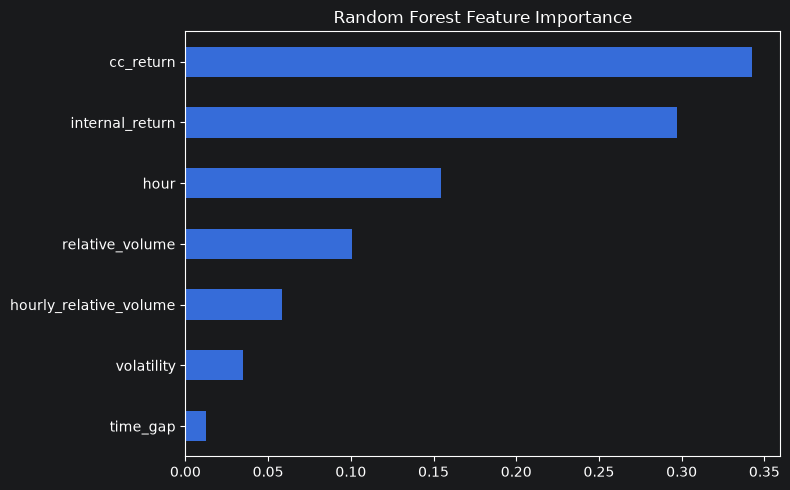

In [97]:
model_name = "Random Forest"
importance.sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    title=f"{model_name} Feature Importance"
)

plt.tight_layout()
plt.show()

In [98]:
print("Best parameters:", clf_grid.best_params_)
print("Best CV balanced accuracy:", clf_grid.best_score_)

best_clf = clf_grid.best_estimator_

print("Training accuracy:", best_clf.score(X_train, y_train))
print("Test accuracy:", best_clf.score(X_test, y_test))
print("Predicted classes:", np.unique(best_clf.predict(X_test), return_counts=True))

Best parameters: {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 200}
Best CV balanced accuracy: 0.5313283212846194
Training accuracy: 0.5343082894372054
Test accuracy: 0.5211033335643496
Predicted classes: (array([0., 1.]), array([7679, 6750]))
